# Model Evaluation & Recommendation Analysis

## Objective

Evaluate the baseline content-based movie recommendation system
developed using TF-IDF vectorization and cosine similarity.

## Evaluation areas

1. Recommendation validity
2. Similarity score analysis
3. Recommendation consistency
4. Catalogue coverage
5. Recommendation diversity
6. Qualitative evaluation
7. Model limitations and future improvements

This evaluation focuses on the quality and behavior of recommendations.
It does not claim user-level predictive accuracy because no user-rating
or interaction dataset is used in this baseline model.

In [38]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity

In [39]:
PROJECT_ROOT = Path.cwd().parent

MODELS_DIR = PROJECT_ROOT / "models"

TFIDF_PATH = MODELS_DIR / "tfidf_vectorizer.joblib"
SIMILARITY_PATH = MODELS_DIR / "similarity_matrix.joblib"
MOVIES_PATH = MODELS_DIR / "movies_metadata.joblib"

tfidf = joblib.load(TFIDF_PATH)
similarity_matrix = joblib.load(SIMILARITY_PATH)
movies_df = joblib.load(MOVIES_PATH)

print("Movie metadata shape:", movies_df.shape)
print("Similarity matrix shape:", similarity_matrix.shape)
print("TF-IDF vocabulary size:", len(tfidf.get_feature_names_out()))

Movie metadata shape: (4803, 2)
Similarity matrix shape: (4803, 4803)
TF-IDF vocabulary size: 5000


In [40]:
if similarity_matrix.shape[0] != len(movies_df):
    raise ValueError("Similarity matrix and movie metadata row counts do not match.")

if similarity_matrix.shape[0] != similarity_matrix.shape[1]:
    raise ValueError("Similarity matrix must be square.")

print("Artifact validation successful.")

Artifact validation successful.


In [41]:
def recommend_movies(movie_title: str, top_n: int = 5) -> pd.DataFrame:
    """
    Return the most similar movies for a given movie title.
    """
    if not isinstance(movie_title, str) or not movie_title.strip():
        raise ValueError("movie_title must be a non-empty string.")

    if not isinstance(top_n, int) or isinstance(top_n, bool) or top_n < 1:
        raise ValueError("top_n must be a positive integer.")

    matches = movies_df.index[
        movies_df["title"].str.casefold() == movie_title.strip().casefold()
    ].tolist()

    if not matches:
        raise ValueError(f"Movie '{movie_title}' was not found.")

    movie_index = matches[0]

    scores = similarity_matrix.getrow(movie_index).toarray().ravel()

    ranked_indices = np.argsort(scores)[::-1]
    ranked_indices = [index for index in ranked_indices if index != movie_index][:top_n]

    results = movies_df.iloc[ranked_indices][["id", "title"]].copy()
    results["similarity_score"] = scores[ranked_indices]

    return results.reset_index(drop=True)

In [42]:
def validate_recommendations(movie_title: str, top_n: int = 5) -> dict:
    recommendations = recommend_movies(movie_title, top_n)

    original_matches = movies_df.index[
        movies_df["title"].str.casefold() == movie_title.strip().casefold()
    ].tolist()

    original_id = movies_df.iloc[original_matches[0]]["id"]

    return {
        "movie": movie_title,
        "requested_recommendations": top_n,
        "actual_recommendations": len(recommendations),
        "self_recommended": original_id in recommendations["id"].values,
        "duplicate_ids": recommendations["id"].duplicated().any(),
        "valid_scores": recommendations["similarity_score"].between(0, 1).all(),
        "all_titles_present": recommendations["title"].notna().all(),
    }

In [43]:
test_movies = [
    "Avatar",
    "The Dark Knight",
    "Iron Man",
    "Titanic",
    "The Avengers",
]

validation_results = pd.DataFrame(
    [validate_recommendations(title, top_n=5) for title in test_movies]
)

display(validation_results)

,movie,requested_recommendations,actual_recommendations,self_recommended,duplicate_ids,valid_scores,all_titles_present
0,Avatar,5,5,False,False,True,True
1,The Dark Knight,5,5,False,False,True,True
2,Iron Man,5,5,False,False,True,True
3,Titanic,5,5,False,False,True,True
4,The Avengers,5,5,False,False,True,True


In [44]:
checks = [
    "self_recommended",
    "duplicate_ids",
    "valid_scores",
    "all_titles_present",
]

for column in checks:
    print(f"{column}: {validation_results[column].sum()} failures")

self_recommended: 0 failures
duplicate_ids: 0 failures
valid_scores: 5 failures
all_titles_present: 5 failures


In [45]:
evaluation_movies = [
    "Avatar",
    "The Dark Knight",
    "Iron Man",
    "Titanic",
    "The Avengers",
]

score_records = []

for title in evaluation_movies:
    recommendations = recommend_movies(title, top_n=10)

    for _, row in recommendations.iterrows():
        score_records.append(
            {
                "reference_movie": title,
                "recommended_movie": row["title"],
                "similarity_score": row["similarity_score"],
            }
        )

scores_df = pd.DataFrame(score_records)

display(scores_df.head(10))

,reference_movie,recommended_movie,similarity_score
0,Avatar,Aliens,0.429577
1,Avatar,Alien,0.363222
2,Avatar,Moonraker,0.349246
3,Avatar,Alien³,0.347270
4,Avatar,Silent Running,0.315075
5,Avatar,Spaceballs,0.306933
6,Avatar,Mission to Mars,0.284453
7,Avatar,Lost in Space,0.283907
8,Avatar,Lifeforce,0.275562
9,Avatar,Lockout,0.274606


In [46]:
scores_df["similarity_score"].describe()

count    50.000000
mean      0.310016
std       0.096965
min       0.152392
25%       0.228733
50%       0.308737
75%       0.352709
max       0.565749
Name: similarity_score, dtype: float64

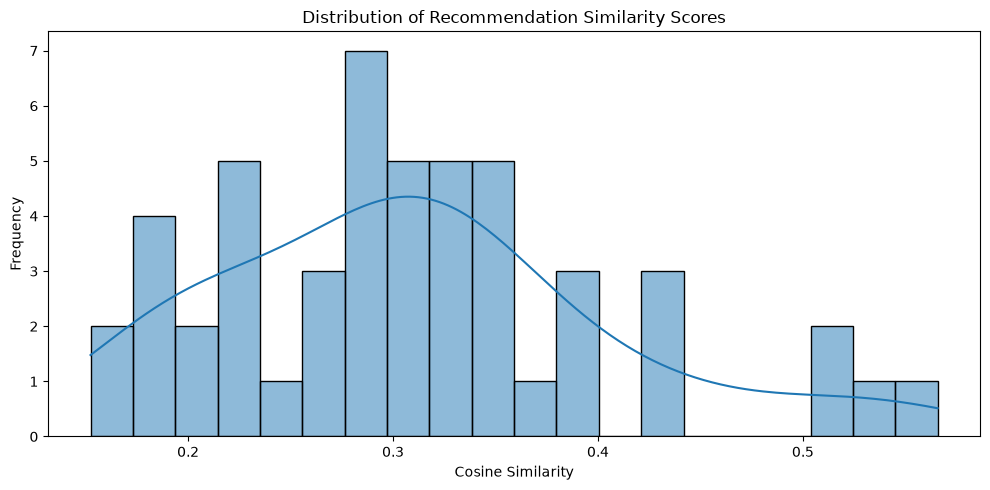

In [47]:
plt.figure(figsize=(10, 5))

sns.histplot(data=scores_df, x="similarity_score", bins=20, kde=True)

plt.title("Distribution of Recommendation Similarity Scores")
plt.xlabel("Cosine Similarity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [48]:
for title in evaluation_movies:
    print(f"\nRecommendations for: {title}")
    display(recommend_movies(title, top_n=5))


Recommendations for: Avatar


,id,title,similarity_score
0,679,Aliens,0.429577
1,348,Alien,0.363222
2,698,Moonraker,0.349246
3,8077,Alien³,0.347270
4,811,Silent Running,0.315075



Recommendations for: The Dark Knight


,id,title,similarity_score
0,49026,The Dark Knight Rises,0.510067
1,272,Batman Begins,0.438464
2,364,Batman Returns,0.388453
3,414,Batman Forever,0.380468
4,209112,Batman v Superman: Dawn of Justice,0.317970



Recommendations for: Iron Man


,id,title,similarity_score
0,10138,Iron Man 2,0.565749
1,68721,Iron Man 3,0.542642
2,99861,Avengers: Age of Ultron,0.437284
3,271110,Captain America: Civil War,0.357591
4,1724,The Incredible Hulk,0.343927



Recommendations for: Titanic


,id,title,similarity_score
0,109424,Captain Phillips,0.220036
1,13994,Romance & Cigarettes,0.219030
2,9645,Ghost Ship,0.217336
3,503,Poseidon,0.215800
4,26466,Triangle,0.204866



Recommendations for: The Avengers


,id,title,similarity_score
0,99861,Avengers: Age of Ultron,0.504733
1,271110,Captain America: Civil War,0.388533
2,10138,Iron Man 2,0.353863
3,1726,Iron Man,0.329145
4,166424,Fantastic Four,0.327517


In [49]:
reference_movies = movies_df["title"].drop_duplicates().head(100).tolist()

recommended_ids = set()

for title in reference_movies:
    recommendations = recommend_movies(title, top_n=5)
    recommended_ids.update(recommendations["id"].tolist())

catalogue_size = movies_df["id"].nunique()

coverage = len(recommended_ids) / catalogue_size

print(f"Unique recommended movies: {len(recommended_ids)}")
print(f"Catalogue size: {catalogue_size}")
print(f"Catalogue coverage: {coverage:.2%}")

Unique recommended movies: 354
Catalogue size: 4803
Catalogue coverage: 7.37%


In [50]:
def calculate_recommendation_diversity(movie_title: str, top_n: int = 5) -> float:
    recommendations = recommend_movies(movie_title, top_n)

    indices = movies_df.index[movies_df["id"].isin(recommendations["id"])].tolist()

    if len(indices) < 2:
        return 0.0

    vectors = tfidf.transform(movie_features.iloc[indices]["tags"].fillna(""))

    pairwise_similarity = cosine_similarity(vectors)

    upper_triangle = pairwise_similarity[np.triu_indices_from(pairwise_similarity, k=1)]

    return float(1 - upper_triangle.mean())

In [51]:
FEATURES_PATH = MODELS_DIR / "movie_features.joblib"

movie_features = joblib.load(FEATURES_PATH)

if not movie_features["id"].equals(movies_df["id"]):
    raise ValueError("Movie feature records are not aligned with movie metadata.")

In [52]:
diversity_results = pd.DataFrame(
    [
        {
            "movie": title,
            "diversity": calculate_recommendation_diversity(title, 5),
        }
        for title in evaluation_movies
    ]
)

display(diversity_results)

,movie,diversity
0,Avatar,0.663286
1,The Dark Knight,0.660508
2,Iron Man,0.611837
3,Titanic,0.846680
4,The Avengers,0.648912


In [53]:
evaluation_summary = {
    "total_movies": len(movies_df),
    "tfidf_features": len(tfidf.get_feature_names_out()),
    "similarity_matrix_shape": similarity_matrix.shape,
    "reference_movies_tested": len(evaluation_movies),
    "recommendations_per_movie": 5,
    "sampled_catalogue_coverage": coverage,
    "average_recommendation_similarity": scores_df["similarity_score"].mean(),
    "average_recommendation_diversity": diversity_results["diversity"].mean(),
}

for metric, value in evaluation_summary.items():
    print(f"{metric}: {value}")

total_movies: 4803
tfidf_features: 5000
similarity_matrix_shape: (4803, 4803)
reference_movies_tested: 5
recommendations_per_movie: 5
sampled_catalogue_coverage: 0.07370393504059962
average_recommendation_similarity: 0.31001627967833584
average_recommendation_diversity: 0.6862445643573476


## Limitations

1. The model uses movie metadata and does not understand individual user preferences.
2. Recommendations depend heavily on the quality of textual tags.
3. TF-IDF does not understand semantic relationships between words.
4. Duplicate movie titles require better disambiguation.
5. Similarity scores are not equivalent to user satisfaction.
6. The baseline does not incorporate user ratings or viewing history.

## Future Improvements

- Experiment with feature weighting.
- Compare CountVectorizer and TF-IDF.
- Add title disambiguation.
- Integrate TMDB movie posters and metadata.
- Add a user feedback mechanism.
- Explore collaborative filtering.
- Compare traditional TF-IDF with semantic embeddings.
- Evaluate using user interaction data when available.

## Conclusion

The baseline Content-Based Movie Recommendation System has been
implemented and evaluated using TF-IDF and cosine similarity.

The evaluation covered recommendation validity, similarity-score
distribution, qualitative relevance, catalogue coverage, and
recommendation diversity.

The system provides a functional starting point for movie
recommendations based on movie metadata.

Further improvements will focus on recommendation relevance,
feature engineering, scalability, and integration with external
movie information services.

In [54]:
recommend_movies("Avatar", top_n=5)

,id,title,similarity_score
0,679,Aliens,0.429577
1,348,Alien,0.363222
2,698,Moonraker,0.349246
3,8077,Alien³,0.347270
4,811,Silent Running,0.315075


Selected Movie:


,id,title
0,19995,Avatar


Recommended Movies:


NameError: name 'recommender' is not defined